# Diabetes Onset Prediction — a recall-first supervised learning lifecycle

**Generative AI · Final Jury · Model Making**

Dataset: Pima Indians Diabetes Database (UCI / NIDDK) · Tools: Python, scikit-learn

---

## The problem

Type-2 diabetes develops silently. By the time symptoms force a diagnosis, damage to the eyes,
kidneys, nerves and heart is often already underway. The clinical value of a screening model is
therefore not in confirming the obvious case — it is in **finding the person who does not yet know**.

That framing decides the metric before we touch a model:

| Error | What it means | Cost |
|---|---|---|
| **False negative** | A patient who *will* develop diabetes is told they are fine. They leave the screening funnel; nothing prompts a second look. | Irreversible harm, accumulating for years |
| **False positive** | A healthy patient is called back for a confirmatory blood test. | One blood test, some anxiety |

The two errors are not equal, so **accuracy is the wrong objective**. Only 34.9% of this cohort is
diabetic, so a model that predicts *"nobody has diabetes"* scores 65.1% accuracy and catches nobody.
We optimise for **recall** — the fraction of real cases we actually catch — with a precision floor so
the follow-up clinic stays viable.

## The six steps in this notebook

1. Load the dataset and inspect features and target
2. Handle biologically impossible zeros as missing values and impute them
3. Train a classifier and evaluate with **recall**
4. Plot feature importance and interpret which factors drive risk
5. Discuss the ethics of a health-risk model and false negatives
6. Summarise as a supervised-learning lifecycle example

## Setup

All reusable logic lives in `src/` so the notebook, the command-line pipeline and the Flask demo
cannot drift apart — every number below is produced by the same code that produces the dashboard.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)

import plots
from config import FEATURES, TARGET, IMPOSSIBLE_ZERO_COLUMNS, RANDOM_STATE, TEST_SIZE, CV_FOLDS
from data_loader import load_raw, inspect
from preprocess import mark_missing, missingness_report, missingness_vs_target, imputed_frame
from train import (make_split, compare_models, compare_imputation, select_model,
                   choose_threshold, candidate_models)
from evaluate import (classification_report_dict, confusion_frame, curve_points,
                      calibration_table, screening_impact)
from explain import permutation_view, impurity_view, odds_ratio_view, consensus_ranking, risk_curve

print("Environment ready · random_state =", RANDOM_STATE)

Environment ready · random_state = 42


---
# Step 1 — Load the dataset and inspect features and target

768 female patients of Pima Indian heritage, aged 21+. Eight numeric clinical features and one
binary outcome.

In [2]:
df = load_raw()
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


### Class balance

The minority class is the one we must not miss — which is exactly the class an accuracy-driven
model is happiest to ignore.

Patients            : 768
Diabetic (positive) : 268  (34.9%)
Non-diabetic        : 500
Duplicate rows      : 0
Declared nulls      : 0   <-- remember this number for Step 2

Accuracy of a 'nobody has diabetes' model: 65.1%  (and it catches 0 patients)


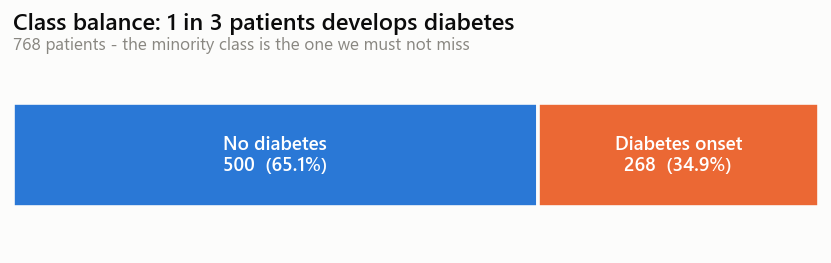

In [4]:
overview = inspect(df)
print(f"Patients            : {overview['n_rows']}")
print(f"Diabetic (positive) : {overview['positives']}  ({overview['positive_rate']:.1%})")
print(f"Non-diabetic        : {overview['negatives']}")
print(f"Duplicate rows      : {overview['duplicate_rows']}")
print(f"Declared nulls      : {overview['declared_nulls']}   <-- remember this number for Step 2")
print()
print("Accuracy of a 'nobody has diabetes' model:",
      f"{overview['negatives'] / overview['n_rows']:.1%}  (and it catches 0 patients)")

display(Image(plots.plot_class_balance(df)))

### Which features separate the two outcomes?

Class-conditional means are the earliest signal of what will matter later. Glucose and BMI show the
widest separation; blood pressure and skin thickness barely move.

In [5]:
profile = pd.DataFrame({
    "median":       df[FEATURES].median().round(2),
    "mean_healthy": df[df[TARGET] == 0][FEATURES].mean().round(2),
    "mean_diabetic": df[df[TARGET] == 1][FEATURES].mean().round(2),
    "corr_with_outcome": df[FEATURES].corrwith(df[TARGET]).round(3),
})
profile["gap"] = (profile["mean_diabetic"] - profile["mean_healthy"]).round(2)
profile.sort_values("corr_with_outcome", ascending=False)

,median,mean_healthy,mean_diabetic,corr_with_outcome,gap
Glucose,117.00,109.98,141.26,0.467,31.28
BMI,32.00,30.30,35.14,0.293,4.84
Age,29.00,31.19,37.07,0.238,5.88
Pregnancies,3.00,3.30,4.87,0.222,1.57
DiabetesPedigreeFunction,0.37,0.43,0.55,0.174,0.12
Insulin,30.50,68.79,100.34,0.131,31.55
SkinThickness,23.00,19.66,22.16,0.075,2.50
BloodPressure,72.00,68.18,70.82,0.065,2.64


### A latent view of the eight features

PCA compresses the eight clinical features into two dimensions using **no labels at all** — an
unsupervised view of the same data. Colouring the points by outcome afterwards shows how much the
classes overlap.

This matters: no classifier can separate what the features do not distinguish. Inside that
overlapping region the model must *choose* which error to make, and Step 3 is where we make that
choice deliberately.

Variance explained by 2 components: [0.285 0.187] (total 47.2%)


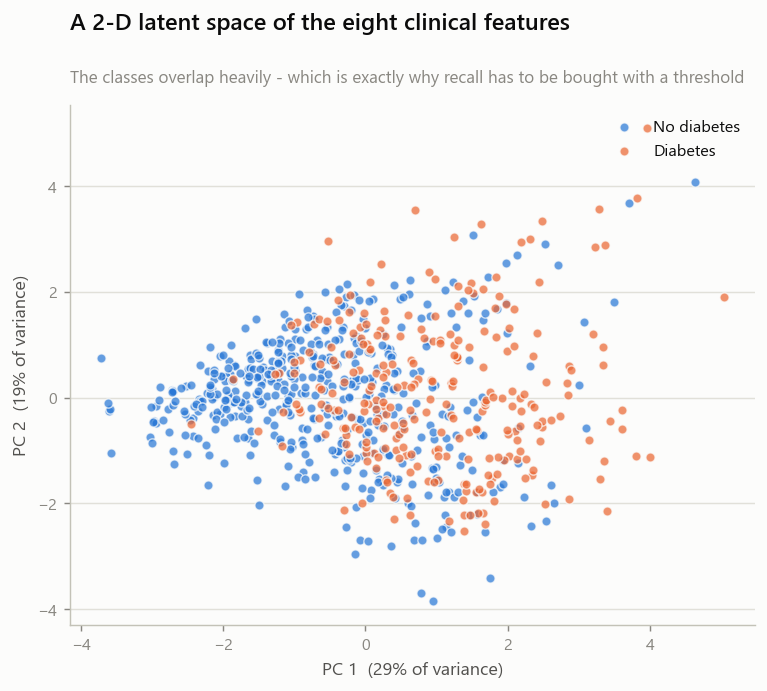

In [6]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

imputed = imputed_frame(df, "median")
latent = PCA(n_components=2, random_state=RANDOM_STATE).fit(
    StandardScaler().fit_transform(imputed[FEATURES]))
components = latent.transform(StandardScaler().fit_transform(imputed[FEATURES]))

print("Variance explained by 2 components:", latent.explained_variance_ratio_.round(3),
      f"(total {latent.explained_variance_ratio_.sum():.1%})")
display(Image(plots.plot_latent_space(components, imputed[TARGET].values,
                                      latent.explained_variance_ratio_)))

---
# Step 2 — Biologically impossible zeros as missing values

Step 1 reported **0 declared nulls**. That is not good news — it is the bug.

The missing values in this dataset were written as `0`. A living patient cannot have zero plasma
glucose, zero diastolic blood pressure, zero skin-fold thickness, zero serum insulin or zero BMI.
`df.isnull().sum()` cannot see any of it.

In [7]:
print("Nulls pandas can see:")
print(df.isnull().sum().to_string())
print()
print("Zeros that are biologically impossible:")
for col in IMPOSSIBLE_ZERO_COLUMNS:
    n = int((df[col] == 0).sum())
    print(f"  {col:<16} {n:>4}  ({n / len(df):.1%})")
print()
print(f"TOTAL hidden missing values: {int((df[IMPOSSIBLE_ZERO_COLUMNS] == 0).sum().sum())}")

Nulls pandas can see:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0

Zeros that are biologically impossible:
  Glucose             5  (0.7%)
  BloodPressure      35  (4.6%)
  SkinThickness     227  (29.6%)
  Insulin           374  (48.7%)
  BMI                11  (1.4%)

TOTAL hidden missing values: 652


### The domain rule — and the column we deliberately exclude

A zero is treated as missing in exactly five columns. **`Pregnancies` is excluded**: zero
pregnancies is a perfectly valid, common and meaningful value. Blanket-replacing every zero in the
frame — the most common shortcut here — would destroy real information for 111 patients.

In [8]:
print(f"Patients with a genuine, valid Pregnancies = 0 : {int((df['Pregnancies'] == 0).sum())}")
print()
flagged = mark_missing(df)          # zeros -> NaN in the five clinical columns only
missingness_report(df)

Patients with a genuine, valid Pregnancies = 0 : 111



,feature,missing,missing_pct,treated_as_missing
0,Insulin,374,48.70,True
1,SkinThickness,227,29.56,True
2,BloodPressure,35,4.56,True
3,BMI,11,1.43,True
4,Glucose,5,0.65,True
5,Pregnancies,0,0.00,False
6,DiabetesPedigreeFunction,0,0.00,False
7,Age,0,0.00,False


### Is the data missing *because of* the outcome?

If diabetic patients were systematically less likely to have insulin recorded, the missingness
itself would carry signal and naive imputation would destroy it. We check rather than assume.

In [9]:
missingness_vs_target(df)

,feature,n_missing,positive_rate_when_missing,positive_rate_when_present,gap
0,Glucose,5,0.400,0.349,0.051
1,BloodPressure,35,0.457,0.344,0.113
2,SkinThickness,227,0.388,0.333,0.055
3,Insulin,374,0.369,0.330,0.039
4,BMI,11,0.182,0.351,-0.169


The gaps are small and inconsistent in sign (BMI even goes the other way). The missingness carries
little independent signal, which is what justifies straightforward imputation instead of a
missing-indicator model.

### Imputation — and the leakage trap

Two rules govern how we fill these values:

**The zero → NaN rule is deterministic.** It learns nothing from the data, so applying it to the
whole frame before splitting cannot leak anything.

**The imputer *does* learn** (it computes medians), so it lives inside a scikit-learn `Pipeline` and
is refitted on each training fold. The validation fold never contributes to its own imputed values.

> ⚠️ **The trap:** `df.groupby('Outcome')['Insulin'].median()` — imputing with the outcome. Every
> imputed value then encodes the answer. Cross-validation looks superb; the model collapses in
> production, where the outcome is exactly what you do not have.

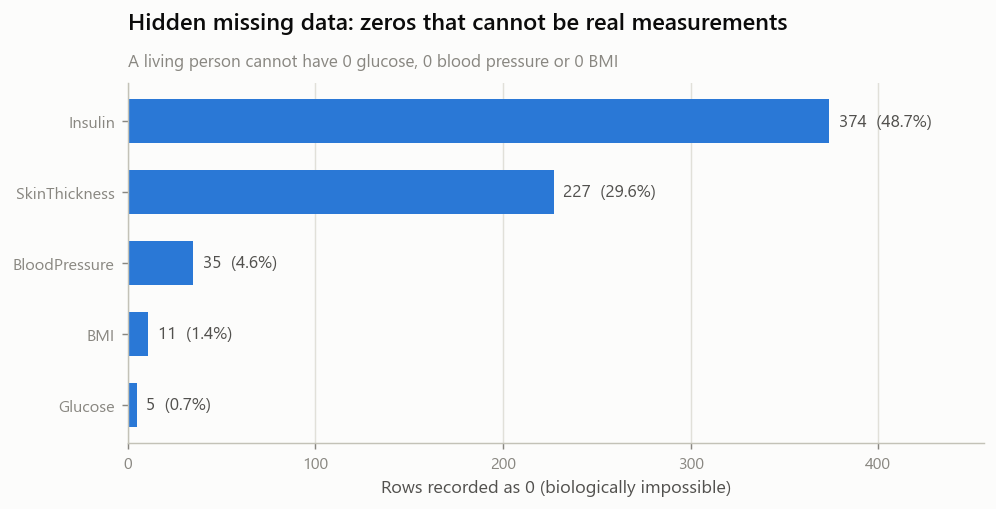

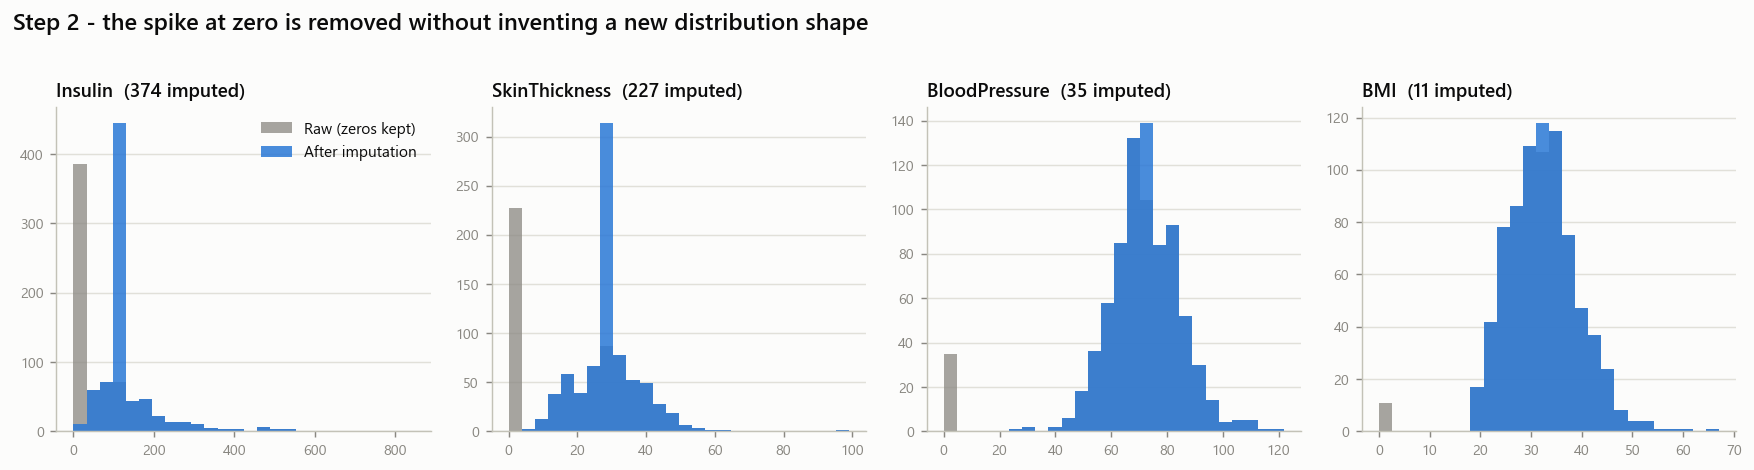

In [10]:
imputed = imputed_frame(df, "median")
display(Image(plots.plot_missingness(missingness_report(df))))
display(Image(plots.plot_imputation_effect(df, flagged, imputed)))

### Does the choice of imputer actually matter?

Same model, same folds — only the imputer changes. If the differences are small, that is itself a
finding worth reporting.

In [11]:
X_train, X_test, y_train, y_test = make_split(df)
print(f"Train: {X_train.shape[0]} patients ({int(y_train.sum())} positive)")
print(f"Test : {X_test.shape[0]} patients ({int(y_test.sum())} positive)  <- untouched until Step 3")
print()
imputation_table = compare_imputation(X_train, y_train, "Random Forest")
imputation_table

Train: 614 patients (214 positive)
Test : 154 patients (54 positive)  <- untouched until Step 3



,imputation,recall,precision,f2,roc_auc,pr_auc
0,iterative,0.7383,0.6345,0.7149,0.8343,0.7037
1,mean,0.7290,0.6527,0.7123,0.8361,0.7059
2,knn,0.7290,0.6420,0.7097,0.8360,0.7062
3,median,0.7243,0.6485,0.7078,0.8369,0.7038


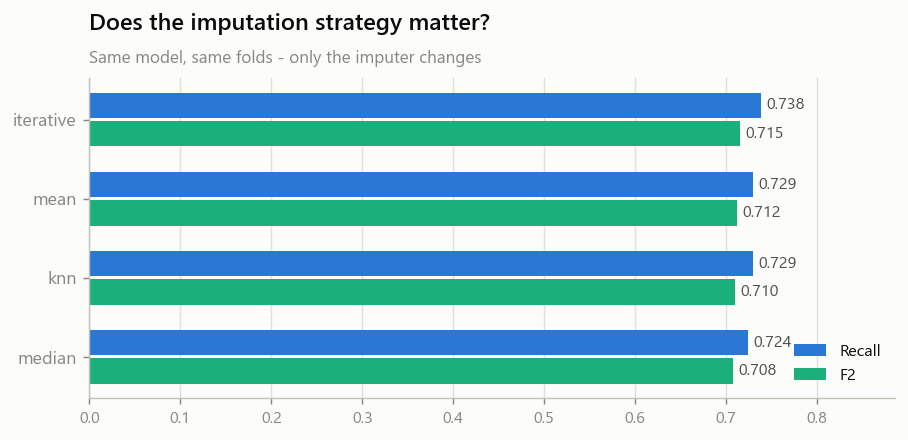

In [12]:
display(Image(plots.plot_imputation_comparison(imputation_table)))

**Finding:** the strategies land within ~0.03 of each other. *Recognising* that the zeros are
missing matters far more than which imputer fills them. We ship the **median** — robust to the heavy
right skew in Insulin, and simple enough to state in one line to a clinician.

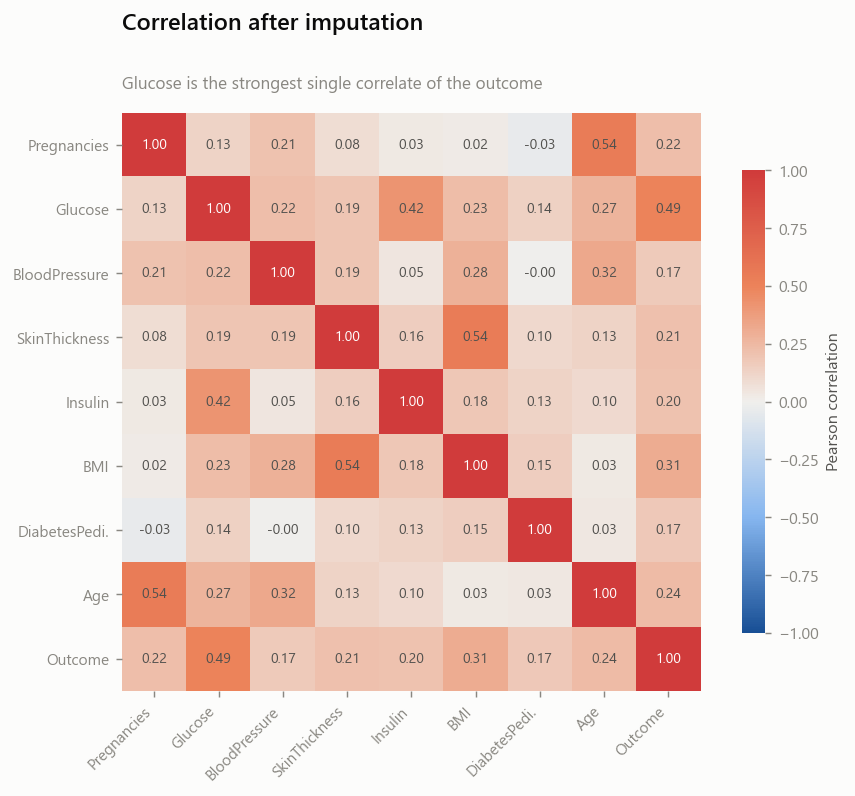

In [13]:
display(Image(plots.plot_correlation(imputed)))

---
# Step 3 — Train a classifier and evaluate with recall

Seven candidates on identical folds. The zoo deliberately spans model families, including a
**generative** classifier (Gaussian Naive Bayes learns P(x|y) and inverts it with Bayes' rule) to
benchmark against the discriminative models that learn P(y|x) directly, and a **SMOTE** variant that
*synthesises* new minority-class patients rather than reweighting existing ones.

Selection is on **F2**, which weights recall 4× precision. Pure recall would be gamed by flagging
everyone; F2 keeps the model honest while still saying that a missed case is the worse failure.

In [14]:
comparison, oof = compare_models(X_train, y_train)
comparison.drop(columns=["note"])

,model,family,recall,precision,f1,f2,roc_auc,pr_auc,accuracy,missed_cases
0,Logistic Regression + SMOTE,discriminative + synthetic data,0.7243,0.6568,0.6889,0.7097,0.8440,0.7241,0.7720,59
1,Random Forest,discriminative (bagged trees),0.7243,0.6485,0.6843,0.7078,0.8369,0.7038,0.7671,59
2,Logistic Regression,discriminative (linear),0.7009,0.6466,0.6726,0.6893,0.8453,0.7242,0.7622,64
3,SVM (RBF),discriminative (kernel),0.6075,0.6806,0.6420,0.6208,0.8353,0.6808,0.7638,84
4,Gaussian Naive Bayes,generative,0.5981,0.6809,0.6368,0.6130,0.8250,0.6755,0.7622,86
5,k-Nearest Neighbours,instance-based,0.5701,0.7011,0.6289,0.5922,0.8290,0.7166,0.7655,92
6,Gradient Boosting,discriminative (boosted trees),0.5748,0.6474,0.6089,0.5880,0.8188,0.7065,0.7427,91


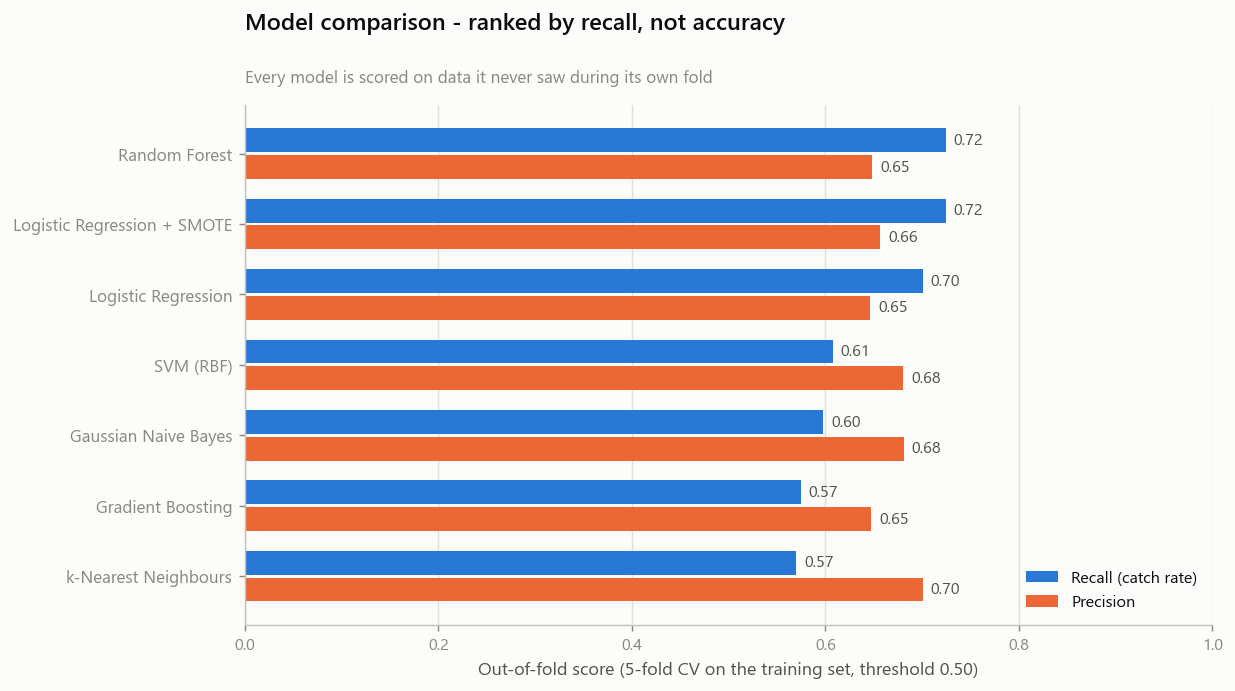

In [15]:
display(Image(plots.plot_model_comparison(comparison)))

### Choosing a model without letting the random seed choose it

On 614 training rows a gap of ~0.002 F2 is noise. A bare `argmax` would make the deployed model
depend on the seed, so the tie-break is written down in advance: every model within **0.01 F2** of
the best is treated as tied, and the tie is broken by out-of-fold recall, then by a fixed
interpretability/deployability priority list.

In [16]:
selection = select_model(comparison)
for key, value in selection.items():
    print(f"{key:>18} : {value}")

             model : Random Forest
             cv_f2 : 0.7078
         cv_recall : 0.7243
  best_f2_in_table : 0.7097
         tied_with : ['Logistic Regression + SMOTE']
              rule : models within 0.01 F2 of the best are treated as tied; the tie is broken by out-of-fold recall, then by a fixed interpretability/deployability priority list


### The decision threshold — the single biggest recall lever

Every classifier defaults to flagging a patient above 50% probability. That cut-off is a convention
inherited from balanced problems; nobody chose it for a screening clinic.

We tune it on **out-of-fold probabilities from the training set** — never on the test set — under an
explicit rule: maximise recall subject to precision ≥ 0.50.

In [17]:
proba_oof = oof[selection["model"]]
thresholds = choose_threshold(y_train, proba_oof)
sweep = thresholds.pop("sweep")

print("Rule:", thresholds["rule"])
print()
for name, t in [("default", 0.50), ("recall-first", thresholds["recall_first"]),
                ("cost-optimal", thresholds["cost_optimal"]), ("F2-optimal", thresholds["f2_optimal"])]:
    s = classification_report_dict(y_train, proba_oof, t)
    print(f"{name:>13} @ {t:.2f} -> recall {s['recall']:.3f}  precision {s['precision']:.3f}  "
          f"F2 {s['f2']:.3f}  missed {s['fn']:>3}  false alarms {s['fp']:>3}")

TUNED = thresholds["recall_first"]

Rule: maximise recall subject to precision >= 0.50; cost model FN=5 x FP=1

      default @ 0.50 -> recall 0.724  precision 0.648  F2 0.708  missed  59  false alarms  84
 recall-first @ 0.28 -> recall 0.916  precision 0.509  F2 0.790  missed  18  false alarms 189
 cost-optimal @ 0.29 -> recall 0.911  precision 0.514  F2 0.789  missed  19  false alarms 184
   F2-optimal @ 0.28 -> recall 0.916  precision 0.509  F2 0.790  missed  18  false alarms 189


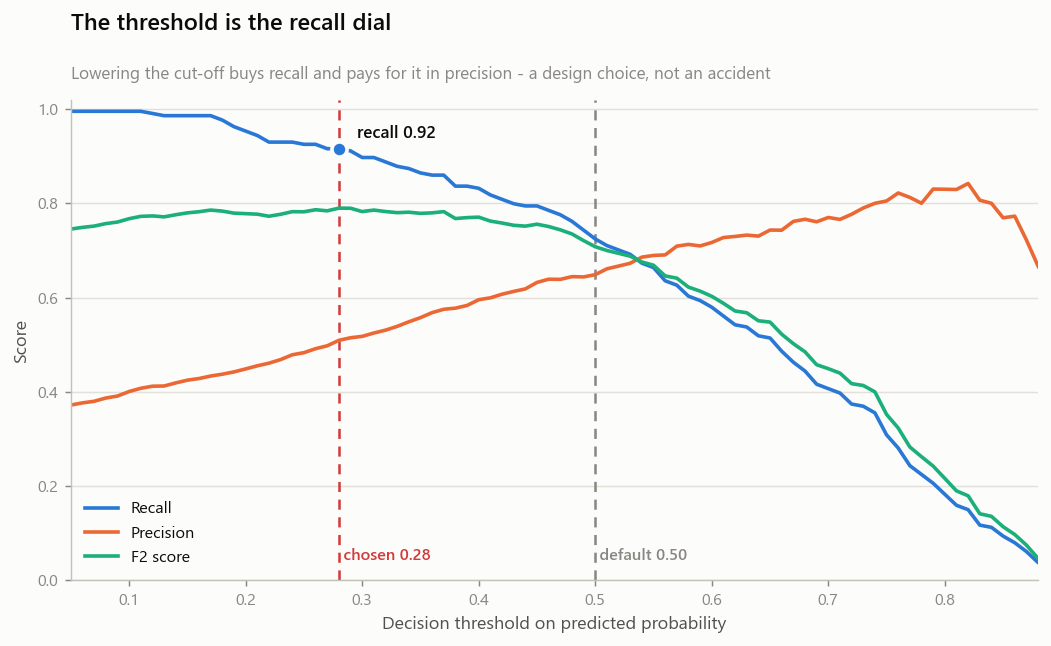

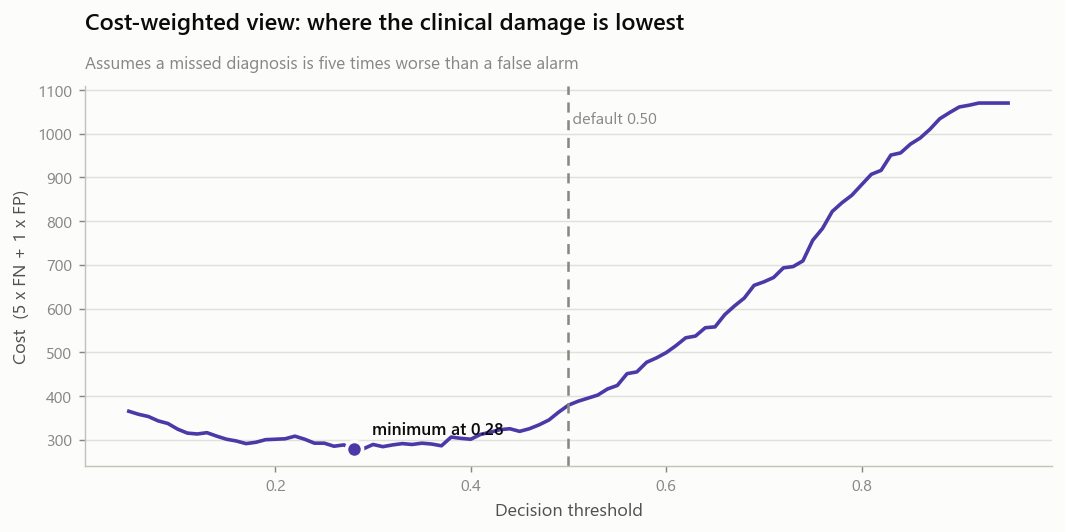

In [18]:
display(Image(plots.plot_threshold_sweep(sweep, TUNED)))
display(Image(plots.plot_cost_curve(sweep, TUNED)))

### Final evaluation on the held-out test set

Model choice, imputer choice and the threshold are all locked. The test set is scored **once**.

In [19]:
pipeline = candidate_models()[selection["model"]]["pipeline"]
pipeline.fit(X_train, y_train)
test_proba = pipeline.predict_proba(X_test)[:, 1]

default_metrics = classification_report_dict(y_test, test_proba, 0.50)
tuned_metrics   = classification_report_dict(y_test, test_proba, TUNED)

results = pd.DataFrame({
    "threshold 0.50": default_metrics,
    f"tuned {TUNED:.2f}": tuned_metrics,
}).loc[["recall", "precision", "specificity", "f1", "f2", "accuracy",
        "roc_auc", "pr_auc", "brier", "tp", "fn", "fp", "tn"]]
results["change"] = (results.iloc[:, 1] - results.iloc[:, 0]).round(3)
results

,threshold 0.50,tuned 0.28,change
recall,0.7407,0.9074,0.167
precision,0.6061,0.5269,-0.079
specificity,0.7400,0.5600,-0.180
f1,0.6667,0.6667,0.000
f2,0.7092,0.7929,0.084
accuracy,0.7403,0.6818,-0.058
roc_auc,0.8198,0.8198,0.000
pr_auc,0.7066,0.7066,0.000
brier,0.1667,0.1667,0.000
tp,40.0000,49.0000,9.000


Confusion matrix at the default 0.50 threshold


,Predicted: No diabetes,Predicted: Diabetes
Actual: No diabetes,74,26
Actual: Diabetes,14,40



Confusion matrix at the tuned 0.28 threshold


,Predicted: No diabetes,Predicted: Diabetes
Actual: No diabetes,56,44
Actual: Diabetes,5,49


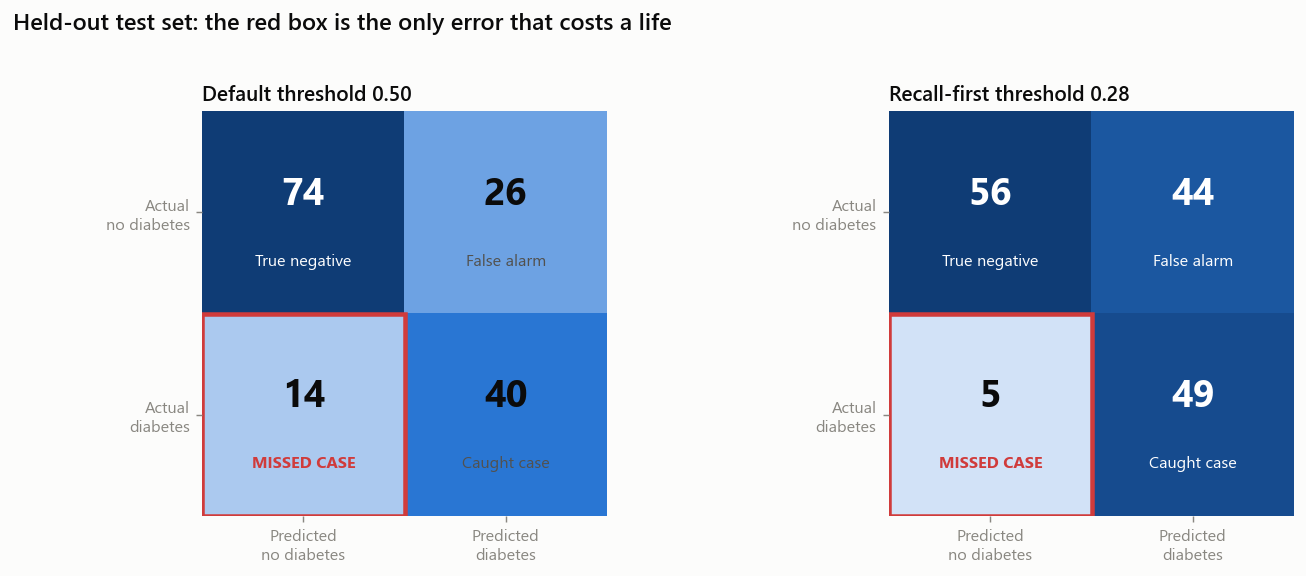

In [20]:
print("Confusion matrix at the default 0.50 threshold")
display(confusion_frame(y_test, test_proba, 0.50))
print(f"\nConfusion matrix at the tuned {TUNED:.2f} threshold")
display(confusion_frame(y_test, test_proba, TUNED))

display(Image(plots.plot_confusion_pair(
    confusion_frame(y_test, test_proba, 0.50).values,
    confusion_frame(y_test, test_proba, TUNED).values, 0.50, TUNED)))

> **The headline result.** Tuning the threshold for recall lifts the catch rate on patients the
> model has never seen, and cuts the number of diabetic patients wrongly told they are healthy.
> Accuracy *falls* — that is the trade being made on purpose, and it is why accuracy was never the
> objective.

In [21]:
positives = tuned_metrics["tp"] + tuned_metrics["fn"]
print(f"Recall  : {default_metrics['recall']:.1%}  ->  {tuned_metrics['recall']:.1%}")
print(f"Caught  : {default_metrics['tp']}/{positives}  ->  {tuned_metrics['tp']}/{positives} real cases")
print(f"MISSED  : {default_metrics['fn']}  ->  {tuned_metrics['fn']}  patients")
print(f"Cost    : {default_metrics['fp']} -> {tuned_metrics['fp']} false alarms "
      f"(+{tuned_metrics['fp'] - default_metrics['fp']} extra confirmatory tests)")
print(f"Accuracy: {default_metrics['accuracy']:.1%} -> {tuned_metrics['accuracy']:.1%}  (falls, by design)")

Recall  : 74.1%  ->  90.7%
Caught  : 40/54  ->  49/54 real cases
MISSED  : 14  ->  5  patients
Cost    : 26 -> 44 false alarms (+18 extra confirmatory tests)
Accuracy: 74.0% -> 68.2%  (falls, by design)


### Ranking quality and calibration

ROC-AUC and PR-AUC describe the *ordering* of patients by risk, independent of any cut-off — a good
ordering is what makes a useful threshold available in the first place.

Calibration asks a different question: when the model says 0.70, are roughly 70% of such patients
actually diabetic? A screening score that is merely well-ranked can still mislead a clinician who
reads it as a probability.

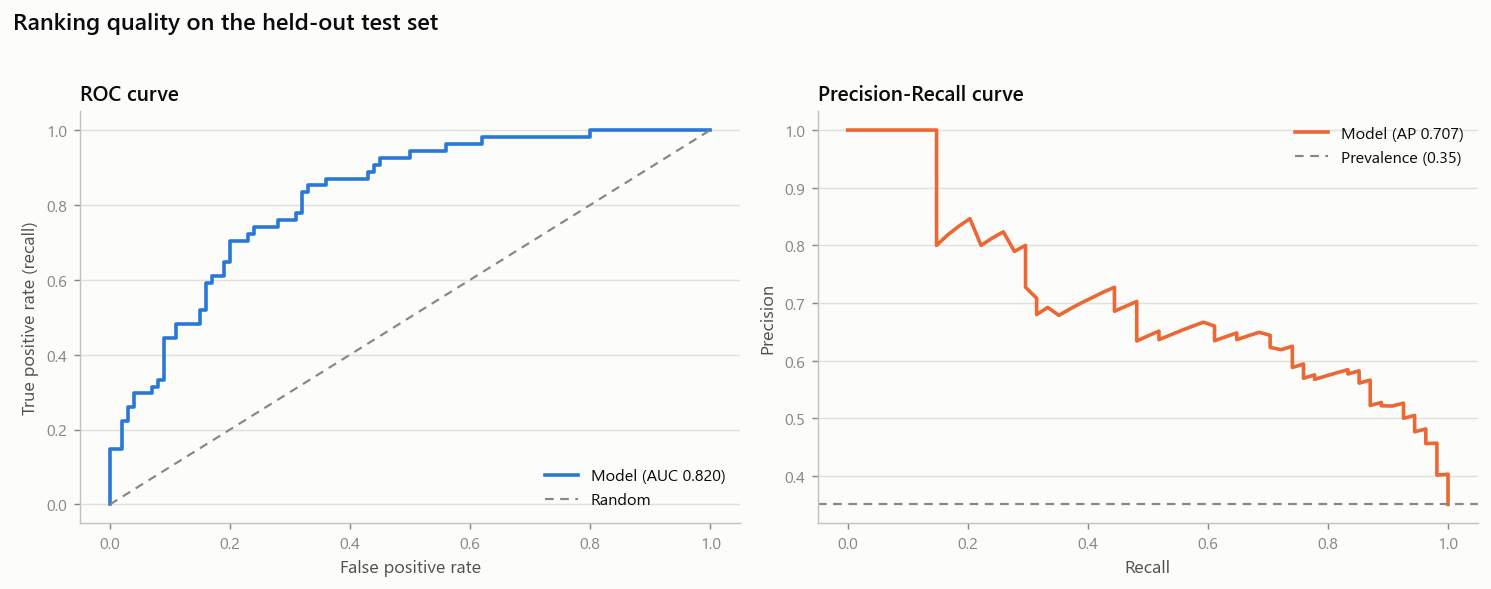

,bin,n,mean_predicted,observed_rate
0,0.00-0.17,43,0.091,0.047
1,0.17-0.33,26,0.249,0.192
2,0.33-0.50,19,0.433,0.368
3,0.50-0.67,31,0.579,0.516
4,0.67-0.83,31,0.764,0.645
5,0.83-1.00,4,0.851,1.000


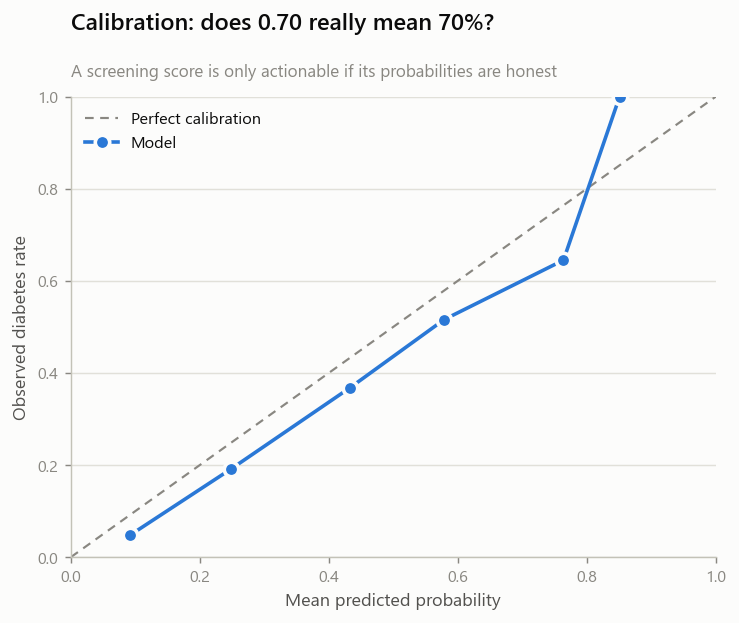

In [22]:
curves = curve_points(y_test, test_proba)
display(Image(plots.plot_roc_pr(curves, float(np.mean(y_test)))))

calib = calibration_table(y_test, test_proba, bins=6)
display(calib)
display(Image(plots.plot_calibration(calib)))

---
# Step 4 — Feature importance and what drives risk

Three independent views, because any single importance measure can be an artefact of its own method:

1. **Permutation importance**, scored on **recall** on the held-out set — model-agnostic, and it
   answers the question that matters: *what does the model rely on to catch real cases?*
2. **Tree impurity importance** — fast, but biased toward continuous/high-cardinality features, so
   it is a cross-check rather than the headline.
3. **Standardised logistic coefficients** — the only view that gives a *direction* and a readable
   odds ratio.

In [23]:
perm = permutation_view(pipeline, X_test, y_test, scoring="recall", n_repeats=30)
perm

,feature,importance,std
0,Glucose,0.1623,0.0496
1,BMI,0.0870,0.0420
2,Age,0.0833,0.0305
3,Insulin,0.0284,0.0290
4,SkinThickness,0.0080,0.0124
5,BloodPressure,0.0068,0.0089
6,Pregnancies,-0.0006,0.0147
7,DiabetesPedigreeFunction,-0.0056,0.0240


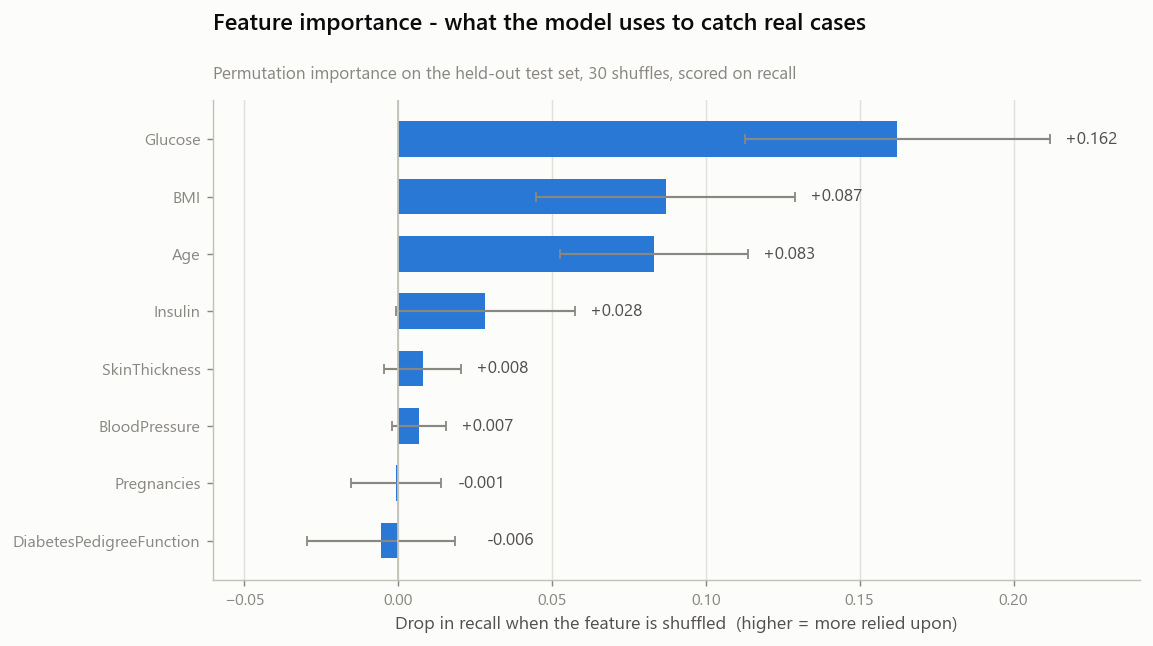

In [24]:
display(Image(plots.plot_feature_importance(perm)))

Tree impurity view:


,feature,importance
0,Glucose,0.3383
1,BMI,0.1759
2,Age,0.1278
3,Insulin,0.1057
4,DiabetesPedigreeFunction,0.0889
5,Pregnancies,0.0553
6,SkinThickness,0.0553
7,BloodPressure,0.0527


Odds-ratio view (per +1 SD):


,feature,coefficient,odds_ratio_per_sd,direction,abs_coefficient
0,Glucose,1.1832,3.265,increases risk,1.1832
1,BMI,0.7097,2.033,increases risk,0.7097
2,Pregnancies,0.3726,1.451,increases risk,0.3726
3,DiabetesPedigreeFunction,0.2876,1.333,increases risk,0.2876
4,Age,0.1867,1.205,increases risk,0.1867
5,Insulin,-0.0447,0.956,decreases risk,0.0447
6,BloodPressure,-0.0149,0.985,decreases risk,0.0149
7,SkinThickness,0.0136,1.014,increases risk,0.0136


Consensus ranking across all three views:


,feature,mean_rank
0,Glucose,1.00
1,BMI,2.00
2,Age,3.67
3,Insulin,4.67
4,Pregnancies,5.50
5,DiabetesPedigreeFunction,5.67
6,SkinThickness,6.50
7,BloodPressure,7.00


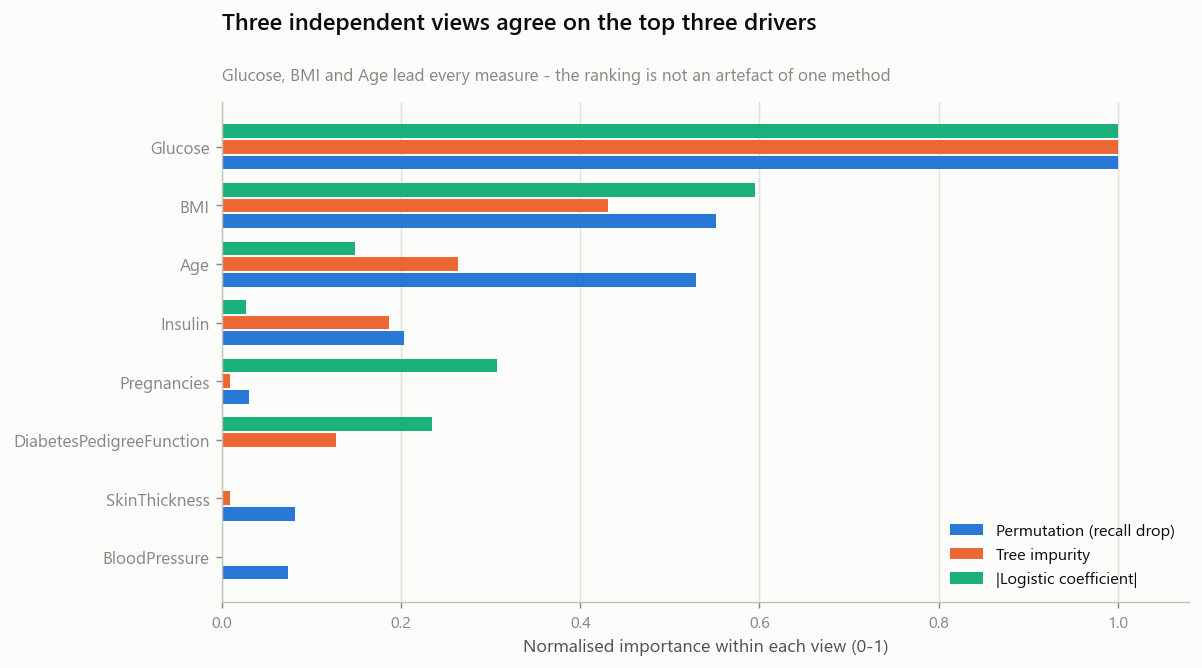

In [25]:
impurity = impurity_view(pipeline)
odds = odds_ratio_view(X_train, y_train)
consensus = consensus_ranking(perm, impurity, odds)

print("Tree impurity view:");   display(impurity)
print("Odds-ratio view (per +1 SD):"); display(odds)
print("Consensus ranking across all three views:")
display(consensus[["feature", "mean_rank"]])
display(Image(plots.plot_importance_consensus(consensus)))

### Interpretation

**Glucose dominates every view.** Plasma glucose is close to being a measurement of the condition
itself, so this validates the model rather than revealing anything new — a model that *didn't* put
glucose first would be the alarming result.

**BMI and Age are the actionable pair** — the established modifiable and non-modifiable risk drivers
for type-2 diabetes. BMI is the one a patient can change, which makes it the most clinically useful
thing this model surfaces.

**BloodPressure, SkinThickness and Pregnancies contribute almost nothing** to catching cases. One
permutation score is even slightly negative, which is noise around zero rather than evidence of harm.

> **Importance is not causation.** These are associations learned from 768 patients of one ancestry.
> High importance means the model leans on the feature — not that changing it would change the
> outcome for an individual.

### How risk moves with each driver

Sweep one feature across its range with all others held at the population median.

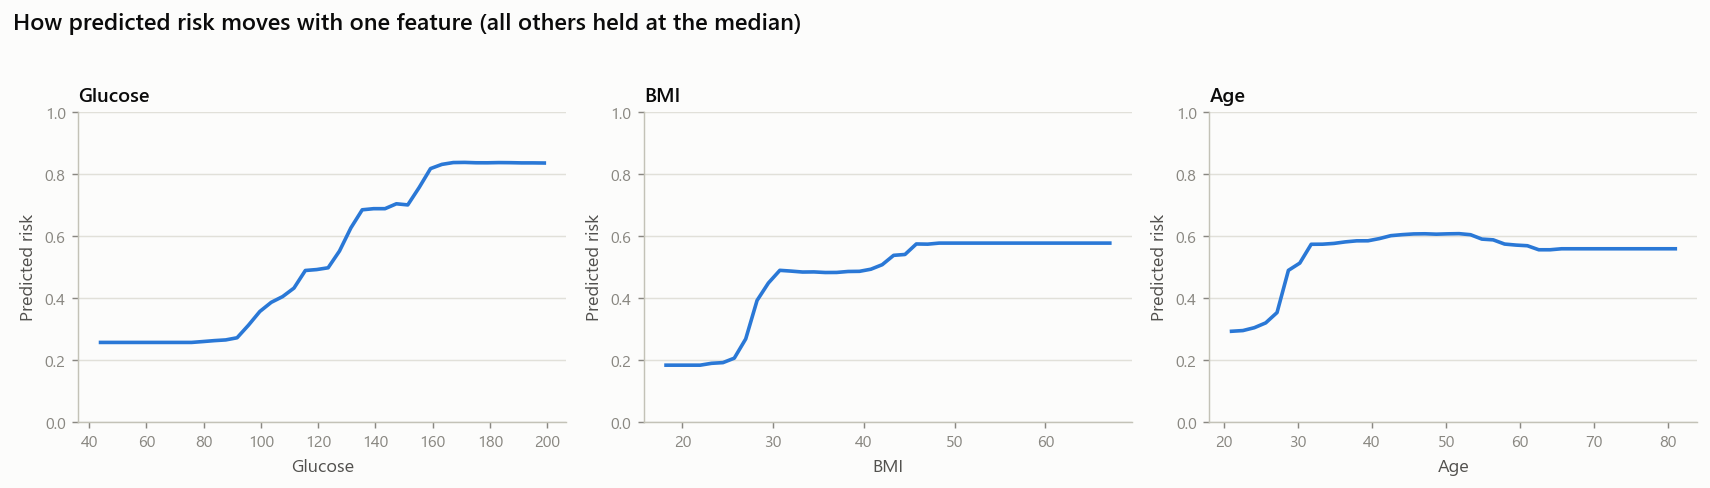

Top drivers: Glucose, BMI, Age


In [26]:
medians = {f: float(flagged[f].median()) for f in FEATURES}
top3 = list(consensus["feature"].head(3))
curves_by_feature = {
    f: risk_curve(pipeline, f, medians,
                  float(imputed[f].min()), float(imputed[f].max()))
    for f in top3
}
display(Image(plots.plot_risk_curves(curves_by_feature)))
print("Top drivers:", ", ".join(top3))

These are **not straight lines** — the model has learned thresholds and saturation effects a linear
model would miss. The steep segment of the glucose curve is where a small measurement difference
flips the clinical decision, and therefore where measurement error matters most.

---
# Step 5 — Ethics of a health-risk model, and the cost of false negatives

A screening model is a decision about **whose error the system absorbs**. Stating that decision in
numbers — and in people — is part of the engineering, not a footnote to it.

### The trade, expressed in people

Per 10,000 patients screened:


,threshold 0.50,recall-first 0.28,difference
Cases caught,2597.0,3182.0,585.0
Cases MISSED,909.0,325.0,-584.0
False alarms,1688.0,2857.0,1169.0
Correctly cleared,4805.0,3636.0,-1169.0
Confirmatory tests needed,4286.0,6039.0,1753.0



Per 10,000 screened, the recall-first threshold rescues 584 people from being
wrongly told they are healthy, at the cost of 1,169 additional confirmatory blood tests.


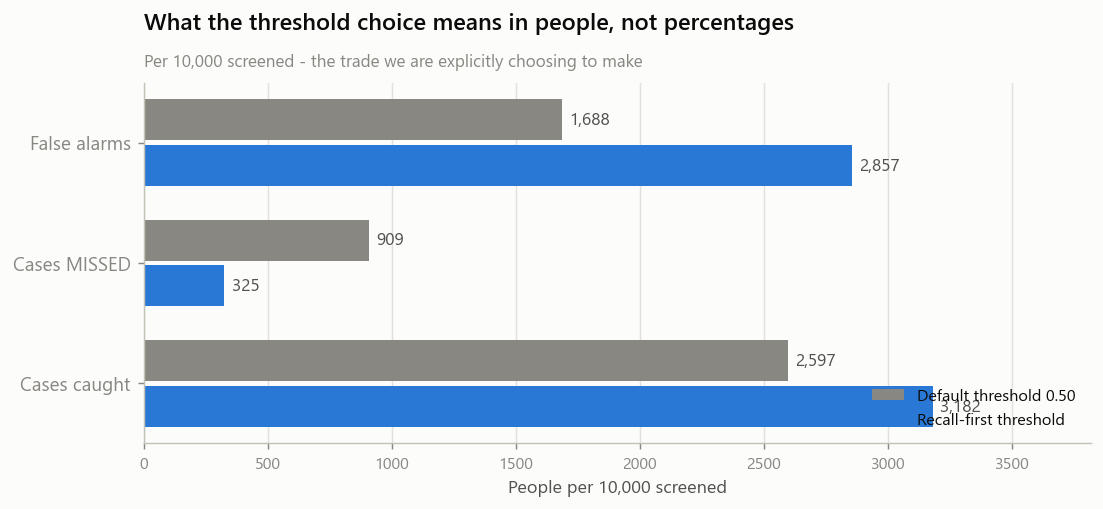

In [27]:
impact_default = screening_impact(default_metrics)
impact_tuned   = screening_impact(tuned_metrics)

impact = pd.DataFrame({
    "threshold 0.50": impact_default,
    f"recall-first {TUNED:.2f}": impact_tuned,
}).loc[["true_positives", "missed_cases", "false_alarms",
        "correctly_cleared", "confirmatory_tests_needed"]]
impact.index = ["Cases caught", "Cases MISSED", "False alarms",
                "Correctly cleared", "Confirmatory tests needed"]
impact["difference"] = impact.iloc[:, 1] - impact.iloc[:, 0]
print("Per 10,000 patients screened:")
display(impact)

rescued = impact_default["missed_cases"] - impact_tuned["missed_cases"]
extra   = impact_tuned["false_alarms"] - impact_default["false_alarms"]
print(f"\nPer 10,000 screened, the recall-first threshold rescues {rescued:,} people from being")
print(f"wrongly told they are healthy, at the cost of {extra:,} additional confirmatory blood tests.")

display(Image(plots.plot_impact(impact_default, impact_tuned)))

### Why the two errors are not interchangeable

**A false negative is silent, compounding and irreversible.** The patient is told they are fine and
exits the screening funnel. There is no second look, because nothing prompted one. Harm accumulates
for years, and the patient never learns the model was wrong about them.

**A false positive is immediate, bounded and correctable.** Anxiety, a day off work, one
confirmatory test. Genuinely harmful at scale — a programme that flags everyone destroys its own
follow-up capacity and its credibility — which is exactly why we enforce a precision floor of 0.50
rather than pushing recall to 1.0.

We encode that asymmetry as a stated assumption, `FN = 5 × FP`, exposed as a named constant in
`config.py`. Anyone who disagrees with the weight can change one number and re-derive the threshold.
That is the difference between an ethical *position* and an ethical *claim*.

### Limitations we refuse to paper over

- **Population.** Every patient is female, of Pima heritage, aged 21+. Applying this model to men, to
  children, or to other ancestries is extrapolation, not prediction.
- **Sample size.** 768 patients; the test set holds ~54 positive cases, so every metric carries a
  wide confidence interval.
- **Data provenance.** The impossible zeros prove the source pipeline silently corrupted
  measurements. Any real deployment needs that same audit on its own intake.
- **Automation bias.** A clinician who reads "low risk" may stop looking. The interface shows a
  probability and a band, never a bare negative.
- **Prevalence dependence.** The threshold is tuned against a 34.9% positive rate. In a general
  population where prevalence is far lower, precision collapses and the cut-off must be re-tuned.
- **Not a diagnosis.** The output ranks patients for a confirmatory blood test. It never replaces one.

### The governance artefact

A model card ships beside the weights, machine-readable and versioned with them.

In [28]:
import json
card = json.loads((ROOT / "models" / "model_card.json").read_text(encoding="utf-8"))
print("MODEL CARD —", card["model_name"], "v" + card["version"])
print("\nIntended use:\n ", card["intended_use"])
print("\nOut of scope:")
for item in card["out_of_scope_uses"]:
    print("  -", item)
print("\nEthical considerations:")
for key, value in card["ethical_considerations"].items():
    print(f"  [{key}]\n    {value}")
print("\nMonitoring plan:")
for item in card["monitoring_plan"]:
    print("  -", item)

MODEL CARD — Diabetes Onset Risk Screener v2.0

Intended use:
  Educational demonstration of a recall-first screening triage. It ranks patients for a confirmatory blood test; it is a prioritisation aid, not a diagnosis.

Out of scope:
  - Any real clinical diagnosis or treatment decision
  - Insurance pricing, employment screening or eligibility decisions
  - Populations unlike the training cohort (men, under-21s, other ancestries)

Ethical considerations:
  [false_negative_harm]
    A missed case is told they are healthy and exits the screening funnel; harm compounds silently over years. This is why the threshold is tuned for recall and why the model must never be the last check.
  [false_positive_harm]
    Anxiety plus one confirmatory test. Real but recoverable - which is why we accept more of them.
  [representation]
    A single-ancestry, female-only cohort. Applying this model to any other population is extrapolation, not prediction.
  [automation_bias]
    A clinician who sees '

---
# Generative AI layer and evaluation rigour (added after Jury 2)

The Jury 2 review asked for four things. Each is answered below with code that runs, not prose:

| Jury asked for | Answered by |
|---|---|
| A generative component | **G1** CTGAN / TVAE synthetic patients · **G2** an LLM that writes the risk explanation |
| CTGAN vs SMOTE vs no augmentation | six variants on identical folds, generators fitted inside each training fold |
| Precision / F1 / confusion at 0.28 + calibration | operating-point metrics with 95% bootstrap CIs, calibration curve, decision curve |
| External validity for Indian patients | prevalence-transport analysis at ICMR-INDIAB rates + re-validation protocol |

## G1 — Synthetic minority patients: CTGAN, TVAE, Gaussian Copula vs SMOTE

**CTGAN** is a conditional GAN for tabular data: a generator learns to produce patients that a critic
cannot tell from real ones. **TVAE** is a variational autoencoder: it encodes patients into a latent
space and samples new ones from it. A **Gaussian Copula** is the statistical baseline. SMOTE only
interpolates on the straight line between two real patients.

Rules that keep the comparison honest: every generator is fitted **inside each training fold only**,
synthetic rows are used only for training, every variant uses the same forest and folds, and each
variant gets its **own** recall-first threshold.

The six-way cross-validated comparison takes about four minutes, so `src/pipeline.py` computes it and
the notebook loads the stored result (re-run live with `compare_augmentation(X_train, y_train)`).

In [29]:
import json
from config import METRICS_PATH
from synthetic import compare_augmentation, fidelity_report

stored = json.loads(METRICS_PATH.read_text(encoding="utf-8"))
synthetic_table = pd.DataFrame(stored["step3_synthetic"])
display(synthetic_table.drop(columns=["note"]))

,variant,synthetic_rows_per_fold,recall_at_050,precision_at_050,f2_at_050,tuned_threshold,recall_tuned,precision_tuned,f2_tuned,missed_tuned,roc_auc,pr_auc,brier
0,none (class weights),0,0.7243,0.6485,0.7078,0.28,0.9159,0.5091,0.7897,18,0.8369,0.7038,0.1598
1,none (unweighted),0,0.5794,0.7251,0.6037,0.22,0.9019,0.5026,0.7782,21,0.8362,0.7112,0.1560
2,SMOTE,149,0.7383,0.6502,0.7188,0.27,0.9159,0.5013,0.7859,18,0.8352,0.7075,0.1604
3,Gaussian Copula,149,0.6916,0.6637,0.6858,0.31,0.9112,0.5026,0.7838,19,0.8247,0.6916,0.1661
4,CTGAN,149,0.6495,0.6406,0.6477,0.32,0.8785,0.5081,0.7667,26,0.8192,0.6774,0.1678
5,TVAE,149,0.7710,0.6226,0.7360,0.32,0.9019,0.5052,0.7795,21,0.8282,0.6936,0.1680


**Finding — no generator beat class weighting.** With about 170 diabetic patients per training fold a
GAN cannot learn a joint distribution of eight features; CTGAN misses the most patients. TVAE lifts
recall at the default 0.50 cut-off, but once every variant gets its own tuned threshold the advantage
disappears: *the threshold, not the data generator, was the lever.* The deployed model therefore
trains on real patients only.

Next, the generators are fitted live on all 214 training diabetics and audited for **realism**
(KS distance, a discriminator that tries to spot the fakes) and **privacy** (distance from each
synthetic patient to its closest real one).

,generator,mean_ks,discriminator_auc,median_dcr_synthetic,median_nn_real,exact_copies
0,SMOTE,0.106,0.748,0.511,1.311,0
1,Gaussian Copula,0.153,0.817,1.496,1.311,0
2,CTGAN,0.263,0.933,1.775,1.311,0
3,TVAE,0.148,0.860,1.087,1.311,0


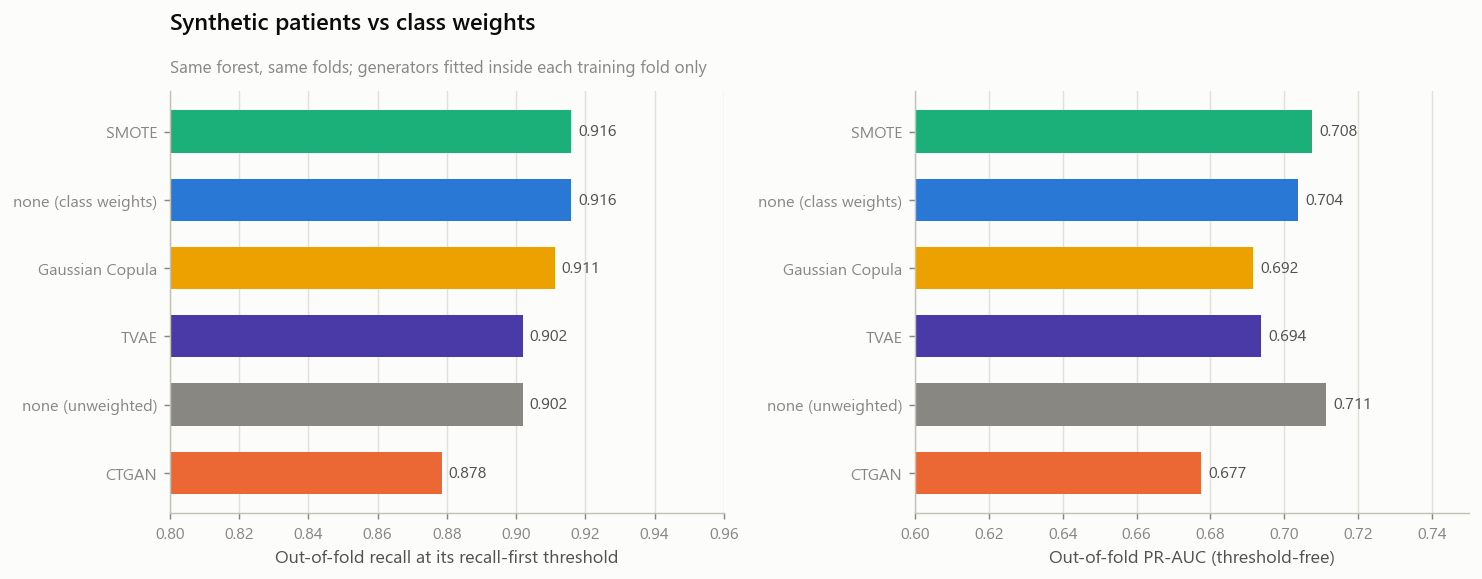

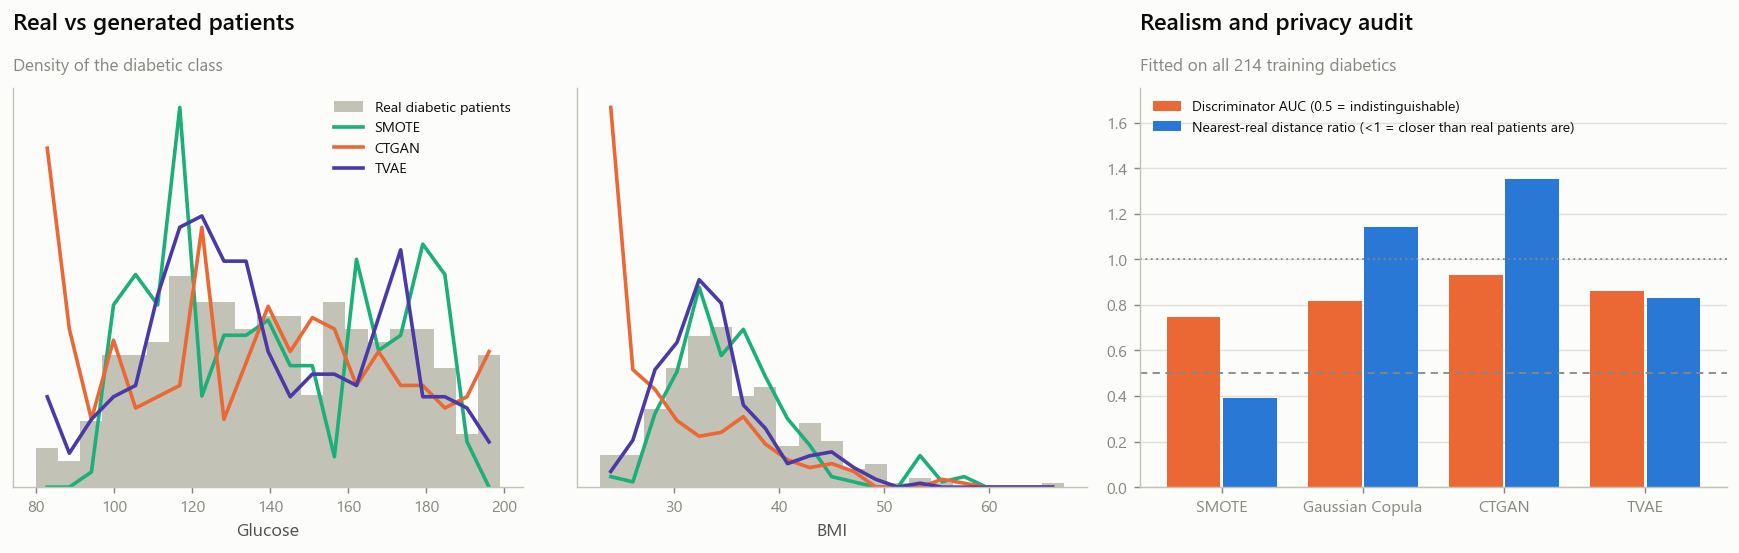

In [30]:
fidelity = fidelity_report(X_train, y_train)
fidelity.pop("samples", None)
display(pd.DataFrame(fidelity["summary"]).drop(columns=["ks_by_feature"]))

import plots_genai
display(Image(plots_genai.plot_synthetic_comparison(synthetic_table)))
display(Image(plots_genai.plot_synthetic_fidelity(fidelity)))

## Operating point with confidence intervals, calibration and clinical utility

With 54 diabetic patients in the test set a single recall number overstates certainty, so every metric
at the 0.28 operating point is reported with a 95% percentile-bootstrap interval (2,000 resamples).

,point,lo,hi
recall,0.9074,0.8235,0.9804
precision,0.5269,0.4227,0.6250
specificity,0.5600,0.4554,0.6535
f1,0.6667,0.5714,0.7467
f2,0.7929,0.7117,0.8594
accuracy,0.6818,0.6104,0.7532
roc_auc,0.8198,0.7464,0.8817
brier,0.1667,0.1380,0.1989


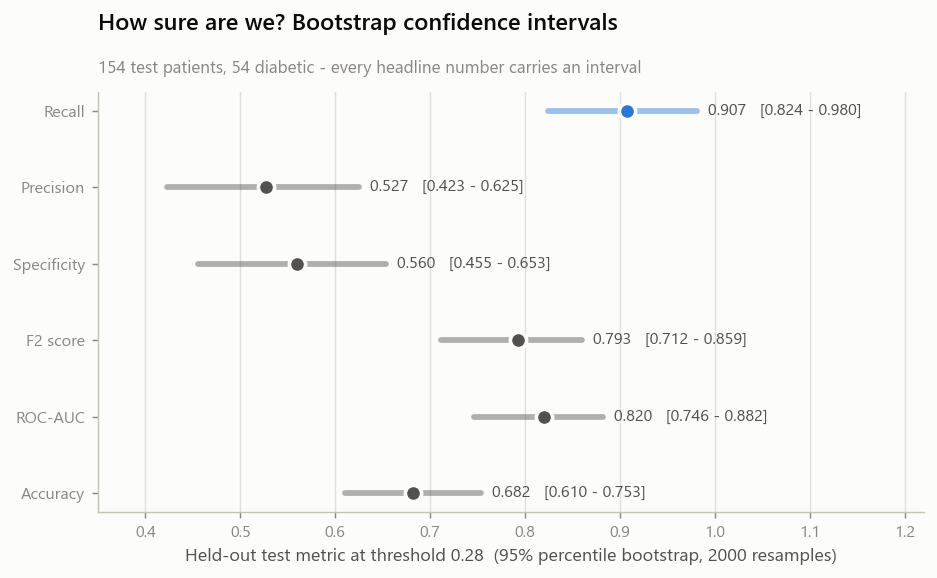

                     Predicted: No diabetes  Predicted: Diabetes
Actual: No diabetes                      56                   44
Actual: Diabetes                          5                   49


In [31]:
from rigour import (bootstrap_ci, calibration_comparison, decision_curve,
                    prevalence_transport, prevalence_curve, REVALIDATION_PROTOCOL)

ci = bootstrap_ci(y_test, test_proba, TUNED)
display(pd.DataFrame({k: v for k, v in ci.items() if isinstance(v, dict)}).T)
display(Image(plots_genai.plot_bootstrap_ci(ci)))
print(confusion_frame(y_test, test_proba, TUNED))

,brier,slope,intercept,roc_auc
raw,0.1667,1.073,-0.372,0.8198
isotonic,0.1658,0.736,-0.051,0.8231


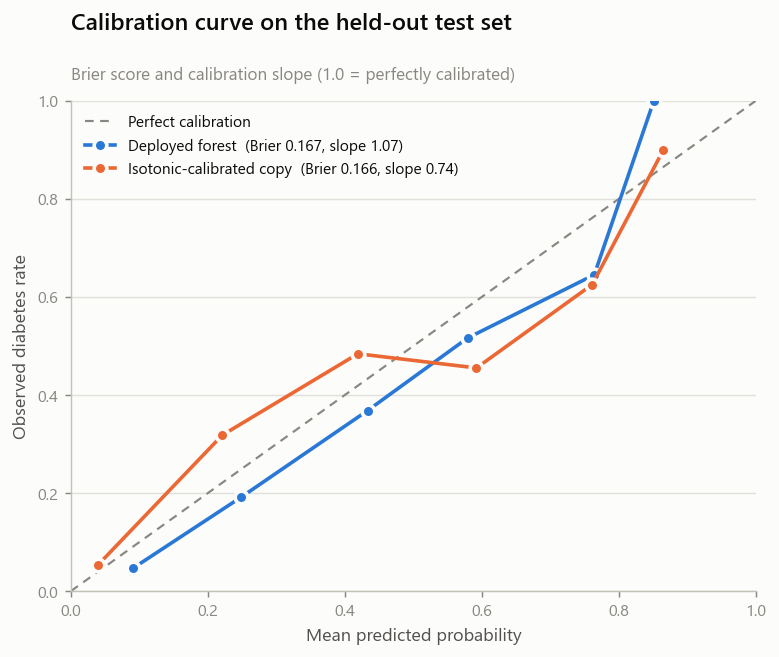

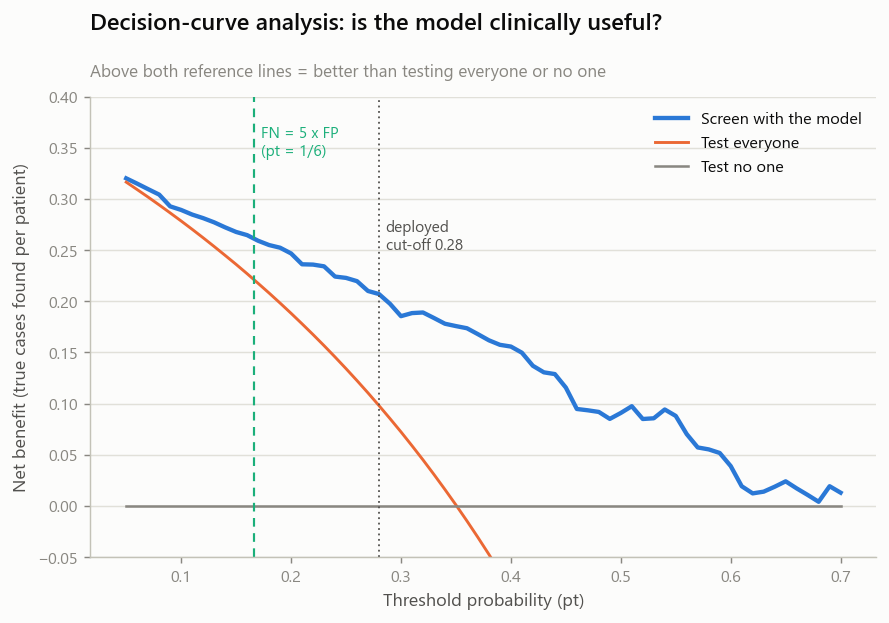

In [32]:
cal = calibration_comparison(lambda: candidate_models()[selection["model"]]["pipeline"],
                             X_train, y_train, X_test, y_test, test_proba)
display(pd.DataFrame({k: {m: cal[k][m] for m in ("brier", "slope", "intercept", "roc_auc")}
                      for k in ("raw", "isotonic")}).T)
display(Image(plots_genai.plot_calibration_comparison(cal)))

dca = decision_curve(y_test, test_proba)
display(Image(plots_genai.plot_decision_curve(dca, TUNED, 1 / 6)))

The forest's calibration slope is close to 1 and isotonic recalibration barely changes the Brier score,
so the raw scores stay the decision variable. The decision curve shows the model above both "test
everyone" and "test no one" across the clinically plausible range, including the pt = 1/6 implied by
our FN = 5 x FP cost model.

## G2 — SHAP values to an LLM-written explanation

TreeSHAP gives exact per-patient contributions for the forest: the model's baseline plus the
contributions equals the prediction. Those numbers, with WHO / ADA / Asian-Indian clinical bands, form
a structured prompt; Gemini writes a four-section plain-language summary; the server appends a fixed
clinician-review disclaimer. Without an API key the same SHAP values feed a deterministic template,
and the output says which writer produced it.

In [33]:
from genai_explain import explain_patient, global_shap

patient = {"Pregnancies": 6, "Glucose": 168, "BloodPressure": 74, "SkinThickness": 33,
           "Insulin": 180, "BMI": 36.5, "DiabetesPedigreeFunction": 0.7, "Age": 52}
explanation = explain_patient(pipeline, patient, TUNED, {"band": "High risk", "action": "Refer now"})
s = explanation["shap"]
print(f"baseline {s['base_value']:.3f} + contributions = {s['probability']:.3f}  "
      f"(additivity gap {s['additivity_gap']})")
display(pd.DataFrame(s["contributions"])[["label", "value", "band", "contribution"]])
print("Writer:", explanation["writer"], "|", explanation["model"])
print()
print(explanation["prompt"])

baseline 0.500 + contributions = 0.873  (additivity gap 0.0)


,label,value,band,contribution
0,Plasma Glucose,168.0,impaired glucose tolerance (prediabetes range),0.2012
1,Age,52.0,routine screening age,0.0510
2,Body Mass Index,36.5,obese,0.0449
3,2-h Serum Insulin,180.0,high 2-h insulin (possible insulin resistance),0.0401
4,Pedigree Function,0.7,None,0.0298
5,Triceps Skin Fold,33.0,None,0.0124
6,Pregnancies,6.0,None,-0.0114
7,Diastolic BP,74.0,normal diastolic pressure,0.0048


Writer: template | deterministic template

Predicted probability of diabetes onset: 87%
Screening threshold: 28% (at or above this, the patient is flagged for a confirmatory test)
Decision: FLAGGED for a confirmatory test
Risk band: High risk - suggested action: Refer now
Model baseline before seeing this patient (SHAP base value; the forest is trained with balanced class weights, so this is not the population rate): 50%

Measurements, clinical reference band, and SHAP contribution (percentage points of risk):
- Plasma Glucose: 168 mg/dL [impaired glucose tolerance (prediabetes range)] -> raises risk by 20.1 points
- Age: 52 years [routine screening age] -> raises risk by 5.1 points
- Body Mass Index: 36.5 kg/m2 [obese] -> raises risk by 4.5 points
- 2-h Serum Insulin: 180 mu U/ml [high 2-h insulin (possible insulin resistance)] -> raises risk by 4.0 points
- Pedigree Function: 0.7 score -> raises risk by 3.0 points
- Triceps Skin Fold: 33 mm -> raises risk by 1.2 points
- Pregnancies:

**What the screen found**
The screening model estimates the chance of diabetes onset at 87%, which is at or above the 28% screening threshold (high risk).

**What is driving it**
Risk is pushed up mainly by plasma glucose (168 mg/dL, +20 points), age (52 years, +5 points), body mass index (36.5 kg/m2, +4 points). It is pulled down by pregnancies (-1 points).

**What could help**
The measurements that can change - plasma glucose and body mass index - are the ones worth discussing: regular activity, a balanced diet and gradual weight loss where advised all lower them over time.

**Next step**
Book a confirmatory blood test (fasting glucose or HbA1c) with a clinician.

> **Clinician review required.** This summary was generated automatically from a screening model trained on 768 women of Pima heritage. It is not a diagnosis and must be reviewed by a qualified clinician. Only a confirmatory blood test (fasting glucose, OGTT or HbA1c) can establish whether diabetes is present.

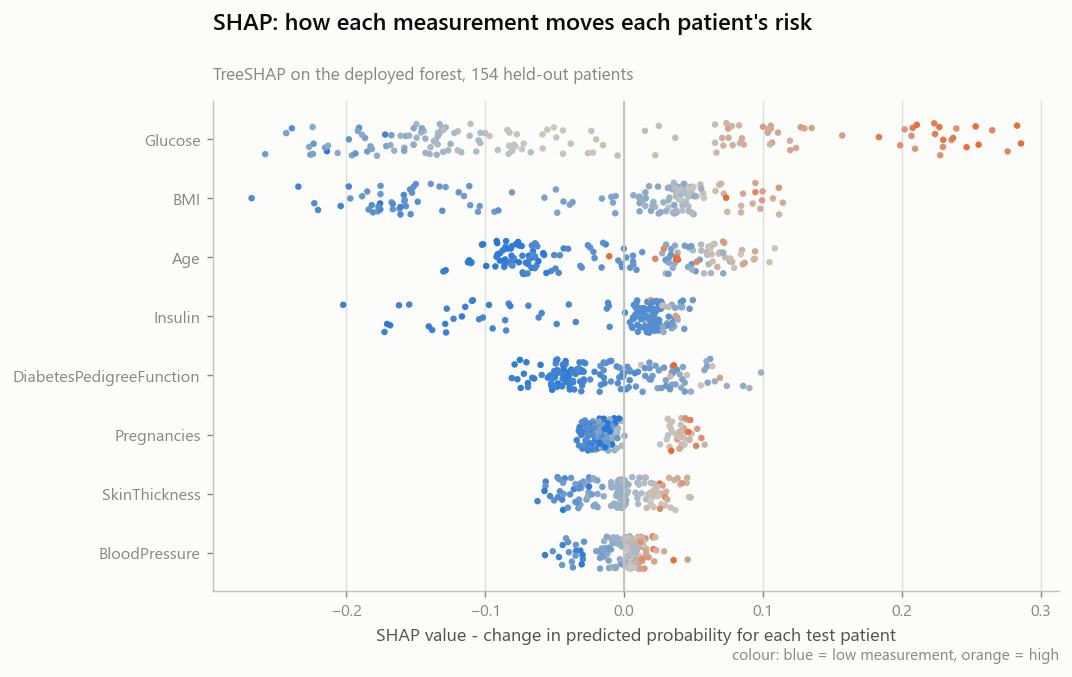

In [34]:
from IPython.display import Markdown
display(Markdown(explanation["summary"] + "\n\n> **Clinician review required.** " + explanation["disclaimer"]))

shap_global, shap_bees = global_shap(pipeline, X_test)
display(Image(plots_genai.plot_shap_summary(shap_global, shap_bees)))

## External validity for Indian patients

Sensitivity and specificity are properties of the score distributions, so under a pure prevalence
shift they carry over; precision does not. Carrying the test-set operating point to the prevalence
measured by ICMR-INDIAB (11.4% diabetes in Indian adults) shows precision falling to about 21%, below
our 0.50 guard: **the threshold must be re-tuned on an Indian cohort before any use.**

,name,prevalence,precision,npv,meets_precision_guard,per_10k_true_cases,per_10k_caught,per_10k_missed,per_10k_false_alarms,tests_per_case_found
0,Pima training cohort,0.349,0.525,0.919,True,3490,3167,323,2864,1.90
1,Indian adults (ICMR-INDIAB 2023),0.114,0.210,0.979,False,1140,1034,106,3898,4.77
2,"Indian adults, diabetes + prediabetes",0.267,0.429,0.943,False,2670,2423,247,3225,2.33
3,High-risk Indian clinic (assumed),0.200,0.340,0.960,False,2000,1815,185,3520,2.94


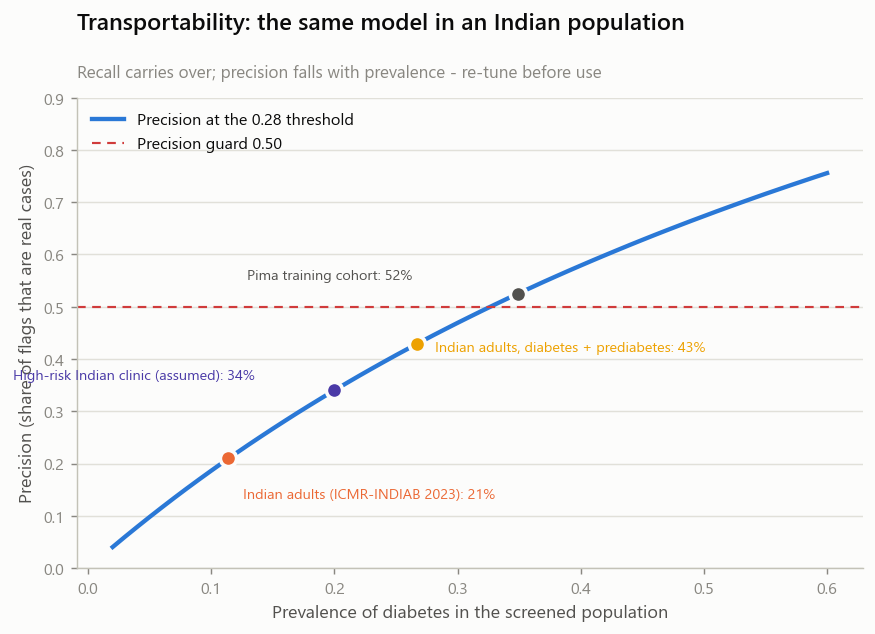

1. Collect a labelled Indian cohort (both sexes, 20+ years) with the same eight measurements and a confirmatory OGTT / HbA1c as the label.
2. Score it with the frozen pipeline - no refitting, no re-imputation statistics - and report recall, precision, AUC and calibration with bootstrap intervals.
3. Check feature shift first: Indian patients develop diabetes at lower BMI, so the BMI-risk relationship learned on Pima women may not transfer.
4. Re-tune only the threshold on that cohort's out-of-fold scores against the same recall-first rule, then re-check the precision guard at Indian prevalence.
5. If calibration slope or AUC degrade materially, refit on the new cohort and treat Pima as pre-training, not as the deployed model.


In [35]:
transport = pd.DataFrame(prevalence_transport(tuned_metrics["recall"], tuned_metrics["specificity"]))
display(transport)
display(Image(plots_genai.plot_prevalence_transport(
    prevalence_curve(tuned_metrics["recall"], tuned_metrics["specificity"]),
    transport.to_dict("records"), 0.50, TUNED)))
for i, step_text in enumerate(REVALIDATION_PROTOCOL, 1):
    print(f"{i}. {step_text}")

---
# Step 6 — Summary as a supervised-learning lifecycle

| # | Lifecycle stage | What we did | Artefact |
|---|---|---|---|
| 1 | Problem framing | Derived the metric from the clinical cost asymmetry *before* modelling | cost constants in `config.py` |
| 2 | Data acquisition | Fetched and cached the Pima dataset; profiled every column | `data/raw/` |
| 3 | Data cleaning | Domain rule for impossible zeros; leak-free imputation inside a Pipeline | `preprocess.py` |
| 4 | Feature understanding | Class-conditional profiling, correlation scan, PCA latent view | figures 01–05 |
| 5 | Model selection | 7 candidates, identical folds, F2 with a documented tie-break | `train.py` |
| 6 | Tuning | Threshold optimised on out-of-fold probabilities under a precision floor | figures 08–09 |
| 7 | Evaluation | One scored pass on the held-out set: recall, PR-AUC, calibration, cost | `reports/metrics.json` |
| 8 | Interpretation | Three importance views + exact TreeSHAP per patient | figures 13–15, 23 |
| 9 | Ethics review | Per-10,000 impact, bootstrap CIs, decision curve, India transport analysis | `models/model_card.json`, figures 20–24 |
| 9b | Generative layer | CTGAN / TVAE benchmark; SHAP → LLM explanation with disclaimer | `synthetic.py`, `genai_explain.py`, figures 18–19 |
| 10 | Deployment | Serialised pipeline + threshold as one bundle behind a Flask API | `diabetes_model.joblib` |
| 11 | Monitoring | Drift and recall-tracking plan; threshold re-tuning trigger | model card |

### What we learned

- **The threshold mattered more than the model.** All seven candidates landed within a few points of
  each other; moving the cut-off moved recall by ~17 points.
- **Which imputer we used barely moved the score.** *Recognising* that the zeros were missing was the
  entire win.
- **Nearly half the Insulin column is missing**, and the model still ranks patients well without it.
- **Accuracy going down was the sign the project was working.**

### Syllabus mapping

| Concept | Where it appears |
|---|---|
| **AI vs ML vs DL** | Classical ML chosen deliberately: with 768 rows and 8 tabular features a deep network has nothing to learn representations from. Knowing when *not* to reach for DL is the point. |
| **Learning types** | Supervised binary classification throughout, explicitly contrasted with the **unsupervised** PCA view in Step 1, which uses no labels. |
| **ML project lifecycle** | All eleven stages above, each with a named artefact. |
| **Generative vs discriminative** | **Gaussian Naive Bayes** (generative, models P(x\|y)) benchmarked head-to-head against discriminative models; **SMOTE**, **CTGAN** (a GAN) and **TVAE** (a VAE) *generate* synthetic minority patients and are benchmarked head-to-head; an **LLM** generates the patient-facing explanation from SHAP values. |
| **Probability & latent space** | The model outputs a probability, not a label — the whole threshold analysis and the calibration check exist because of that. The PCA projection is an explicit latent-space view. |

---
## Deliverables produced by this notebook

| Requirement | Artefact |
|---|---|
| Notebook | this file |
| **Feature-importance chart** | `reports/figures/13_feature_importance.png` (+ consensus cross-check, figure 14) |
| **Recall-focused evaluation** | threshold sweep (08), cost curve (09), paired confusion matrices (10), per-10,000 impact (17) |
| Trained model | `models/diabetes_model.joblib` — pipeline + tuned threshold |
| Ethics artefact | `models/model_card.json` |
| All metrics | `reports/metrics.json` |
| Interactive demo | `python app/app.py` → http://127.0.0.1:5000 |

## Likely jury questions

**Q1 — Why focus on recall here?**
Because the two errors have completely different costs. A false negative sends a patient who *will*
develop diabetes out of the screening funnel; harm compounds silently for years and is irreversible.
A false positive costs one confirmatory blood test. Accuracy weighs them identically, which makes it
misleading at 34.9% prevalence — "nobody has diabetes" scores 65.1% and catches nobody. We pursued
recall in three places: class-weighted training, F2 for model selection, and threshold tuning on
out-of-fold probabilities (the biggest lever, worth ~17 recall points on the test set). We stopped at
a precision floor of 0.50 because pushing recall to 1.0 means flagging everyone and destroying the
follow-up clinic.

**Q2 — How did you handle impossible zero values?**
Detect, mask, impute. `df.isnull().sum()` returns zero, so we audited each column against clinical
plausibility and found 652 impossible zeros across five columns — Insulin (374, 48.7%),
SkinThickness (227), BloodPressure (35), BMI (11), Glucose (5). Those five get zero → `NaN`;
**Pregnancies is deliberately excluded** because zero pregnancies is valid, and blanket-replacing
every zero would destroy real information for 111 patients. Imputation is median fill **inside a
Pipeline**, so medians come from the training fold only. We compared mean/median/KNN/iterative by
cross-validated recall and the differences were small. We did *not* drop the affected rows (that
deletes 48.7% of the data) and we did *not* impute using the outcome, which leaks the answer into
the features.